# Predictive Maintenance — Machine Failure Prediction

EDA and model comparison (Logistic Regression, Decision Tree, Random Forest) on the AI4I 2020 predictive maintenance dataset. The best binary model (Random Forest) is saved to `models/failure_model.pkl` and used by the Streamlit dashboard (`app.py`).

In [98]:
#imports
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import precision_recall_curve, average_precision_score, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer

In [99]:
#load data
df = pd.read_csv('../data/predictive_maintenance.csv')
df


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure
...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,No Failure
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,No Failure
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,No Failure
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,No Failure


In [100]:
# convert temperatures from Kelvin to Celsius
for col in ['Air temperature [K]', 'Process temperature [K]']:
    df[col.replace('[K]', '[°C]')] = df[col] - 273.15
df.drop(columns=['Air temperature [K]', 'Process temperature [K]'], inplace=True)

In [101]:
df

,UDI,Product ID,Type,Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type,Air temperature [°C],Process temperature [°C]
0,1,M14860,M,1551,42.8,0,0,No Failure,24.95,35.45
1,2,L47181,L,1408,46.3,3,0,No Failure,25.05,35.55
2,3,L47182,L,1498,49.4,5,0,No Failure,24.95,35.35
3,4,L47183,L,1433,39.5,7,0,No Failure,25.05,35.45
4,5,L47184,L,1408,40.0,9,0,No Failure,25.05,35.55
...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,1604,29.5,14,0,No Failure,25.65,35.25
9996,9997,H39410,H,1632,31.8,17,0,No Failure,25.75,35.25
9997,9998,M24857,M,1645,33.4,22,0,No Failure,25.85,35.45
9998,9999,H39412,H,1408,48.5,25,0,No Failure,25.85,35.55


In [102]:
# check for missing values
missing_values = df.isnull().sum()
missing_values

UDI                         0
Product ID                  0
Type                        0
Rotational speed [rpm]      0
Torque [Nm]                 0
Tool wear [min]             0
Target                      0
Failure Type                0
Air temperature [°C]        0
Process temperature [°C]    0
dtype: int64

In [103]:
# check for errors in the data 
print(df[df['Failure Type'] == 'No Failure'].groupby('Target').size())
print(df[df['Failure Type'] != 'No Failure'].groupby('Target').size())

#there are errors in the data, we will drop the rows with errors
df = df[~((df['Failure Type'] == 'No Failure') & (df['Target'] == 1))]
df = df[~((df['Failure Type'] != 'No Failure') & (df['Target'] == 0))]


Target
0    9643
1       9
dtype: int64
Target
0     18
1    330
dtype: int64


In [104]:
#check if the rows were dropped are gone
print(df[df['Failure Type'] == 'No Failure'].groupby('Target').size())
print(df[df['Failure Type'] != 'No Failure'].groupby('Target').size())

Target
0    9643
dtype: int64
Target
1    330
dtype: int64


In [105]:
#copy for EDA
df_eda = df.copy()

## Exploratory Data Analysis (EDA)

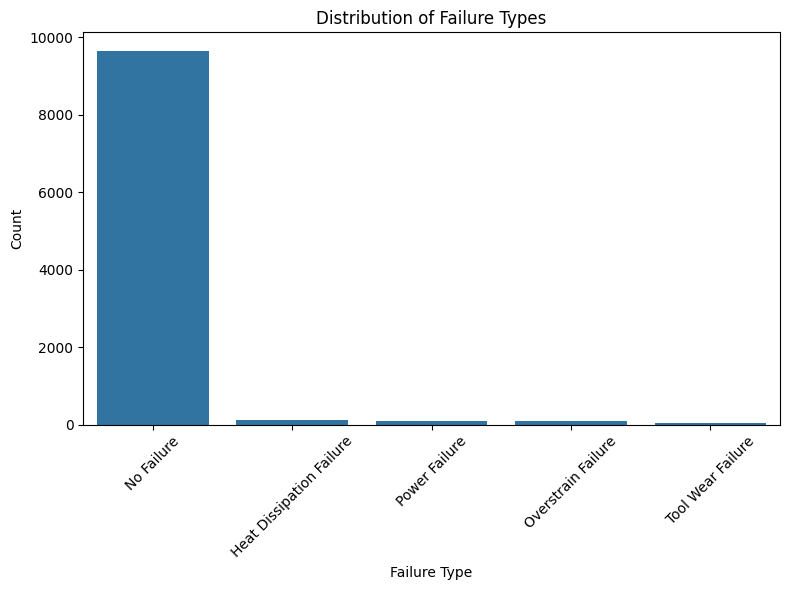

In [106]:
# type of failure distribution
plt.figure(figsize=(8, 6))
sns.countplot(data=df_eda, x='Failure Type', order=df_eda['Failure Type'].value_counts().index)
plt.title('Distribution of Failure Types')
plt.xlabel('Failure Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

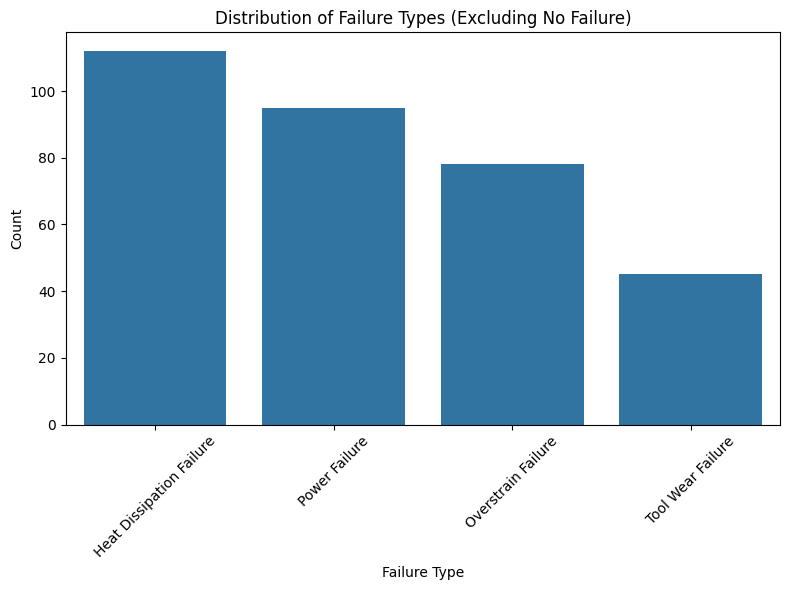

In [107]:
# failure distribution without 'No Failure'
plt.figure(figsize=(8, 6))
sns.countplot(data=df_eda[df_eda['Failure Type'] != 'No Failure'], x='Failure Type', order=df_eda[df_eda['Failure Type'] != 'No Failure']['Failure Type'].value_counts().index)
plt.title('Distribution of Failure Types (Excluding No Failure)')
plt.xlabel('Failure Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

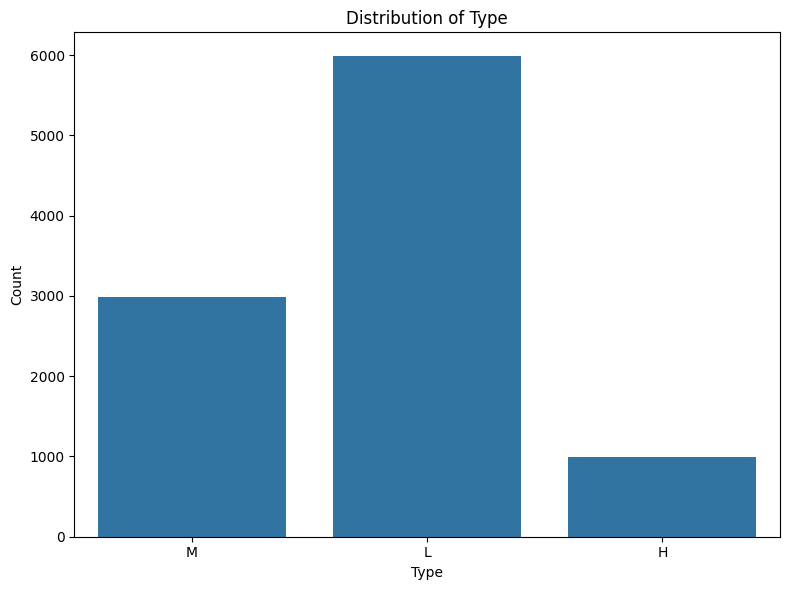

In [108]:
# distribution of 'Type' feature
plt.figure(figsize=(8, 6))
sns.countplot(data=df_eda, x='Type')
plt.title('Distribution of Type')
plt.xlabel('Type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

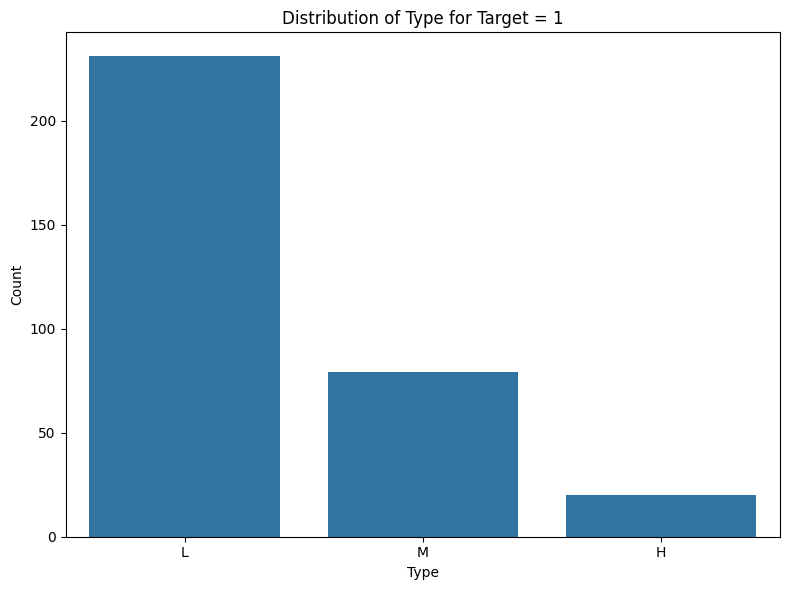

In [109]:
# distribution of 'Type' feature by 'Target' = 1
plt.figure(figsize=(8, 6))
sns.countplot(data=df_eda[df_eda['Target'] == 1], x='Type')
plt.title('Distribution of Type for Target = 1')
plt.xlabel('Type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

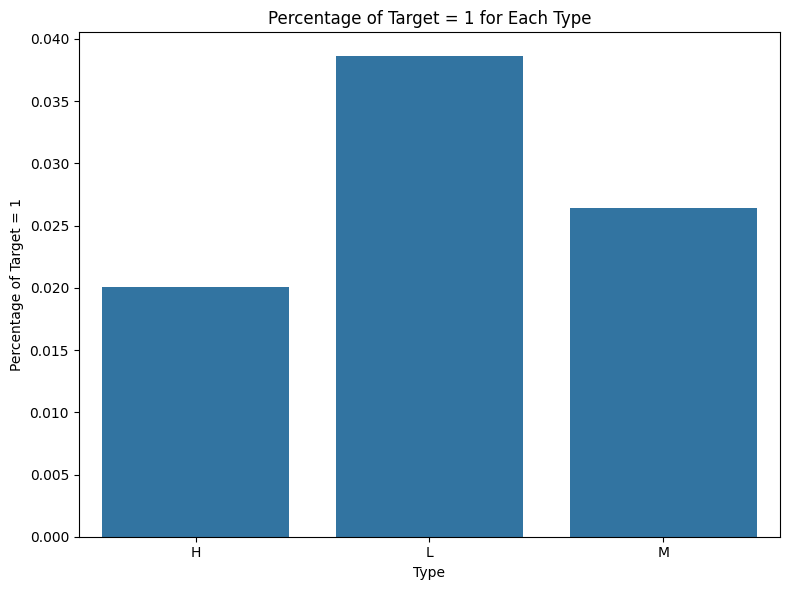

In [110]:
# % of 'Target' = 1 for each 'Type'
type_target_distribution = df_eda.groupby('Type')['Target'].mean().reset_index()
plt.figure(figsize=(8, 6))
sns.barplot(data=type_target_distribution, x='Type', y='Target')
plt.title('Percentage of Target = 1 for Each Type')
plt.xlabel('Type')
plt.ylabel('Percentage of Target = 1')
plt.tight_layout()
plt.show()

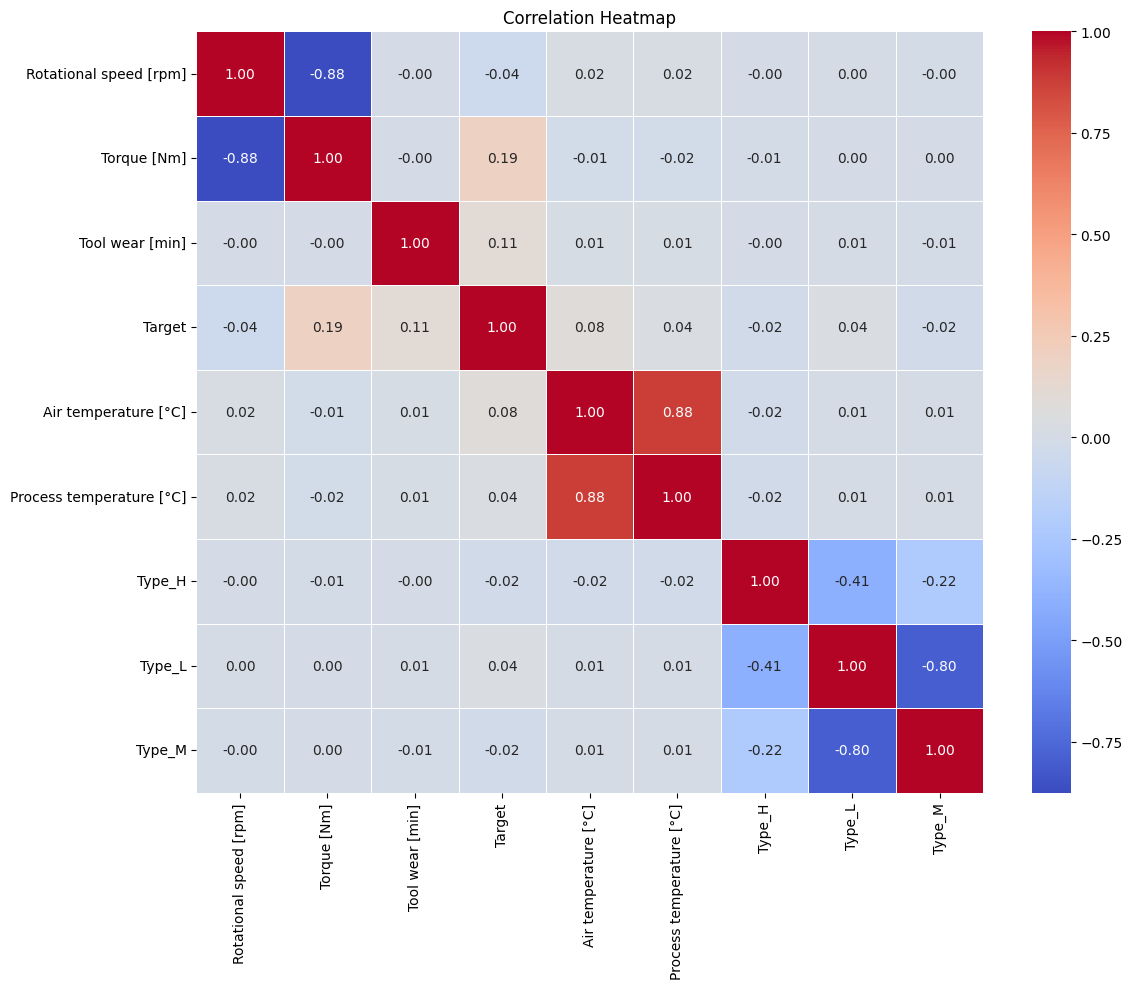

In [111]:
#get dummies for 'Type' feature
df_eda = pd.get_dummies(df_eda, columns=['Type'], drop_first=False)
# correlation heatmap, excluding udi, failure type, prouductid by target
plt.figure(figsize=(12, 10))
corr = df_eda.drop(columns=['UDI', 'Failure Type', 'Product ID']).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

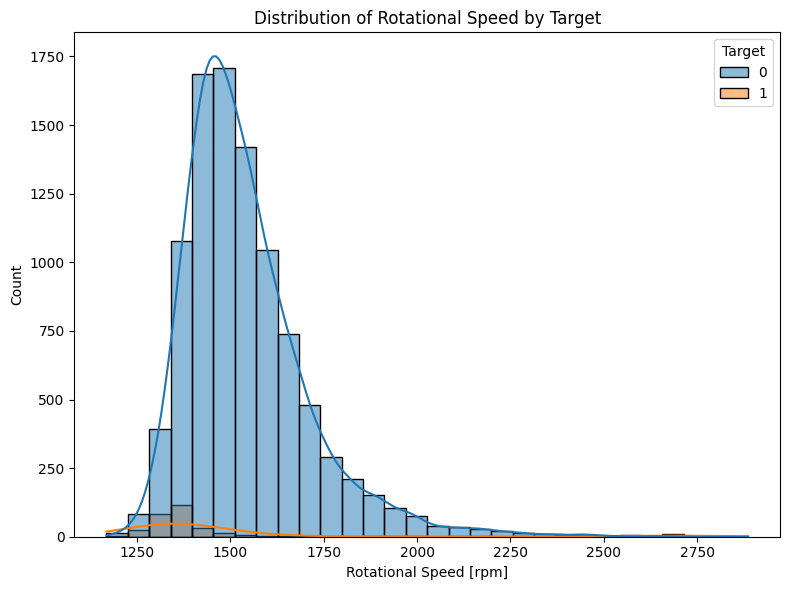

In [112]:
# rotational speed distribution by target
plt.figure(figsize=(8, 6))
sns.histplot(data=df_eda, x='Rotational speed [rpm]', hue='Target', bins=30, kde=True)
plt.title('Distribution of Rotational Speed by Target')
plt.xlabel('Rotational Speed [rpm]')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

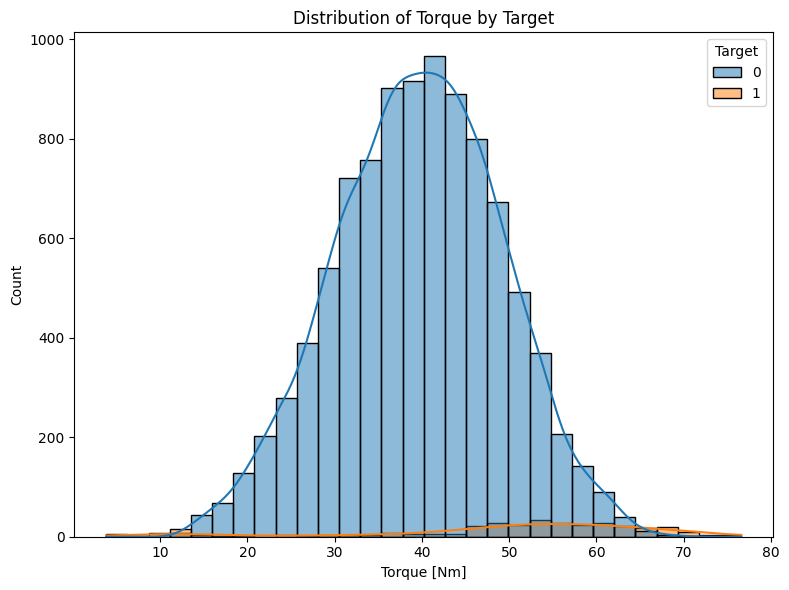

In [113]:
# torque distribution by target
plt.figure(figsize=(8, 6))
sns.histplot(data=df_eda, x='Torque [Nm]', hue='Target', bins=30, kde=True)
plt.title('Distribution of Torque by Target')
plt.xlabel('Torque [Nm]')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

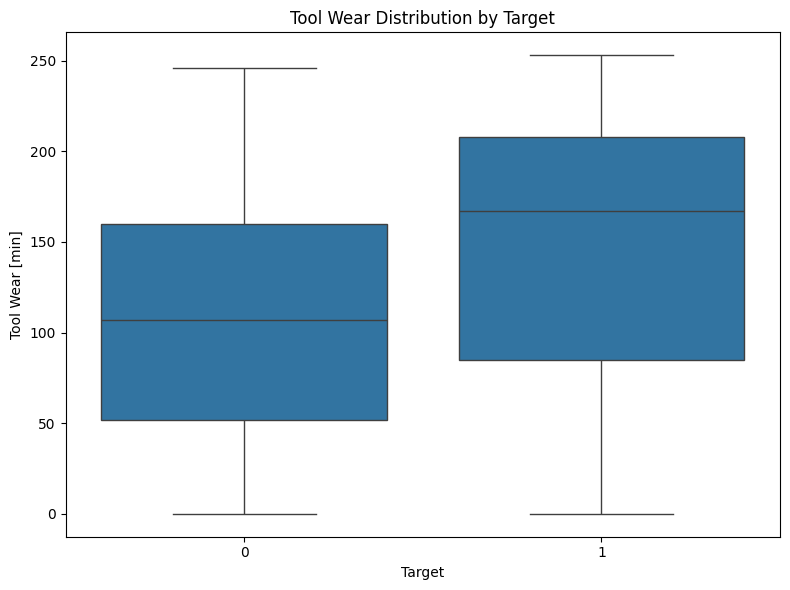

In [114]:
# how much does the tool wear affect the target, pretty and understandble, no histplot
plt.figure(figsize=(8, 6))
sns.boxplot(data=df_eda, x='Target', y='Tool wear [min]')
plt.title('Tool Wear Distribution by Target')
plt.xlabel('Target')
plt.ylabel('Tool Wear [min]')
plt.tight_layout()
plt.show()

## Prediction of 'Target' (if the machine will fail or not)

In [115]:
df_binary = df.drop(columns=['UDI', 'Failure Type', 'Product ID'])
X = df_binary.drop(columns=['Target'])
y = df_binary['Target']

#check for class imbalance
class_counts = y.value_counts()
print("Class distribution:")
print(class_counts)

Class distribution:
Target
0    9643
1     330
Name: count, dtype: int64


In [116]:
#split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#check the shape of the train and test sets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (7978, 6)
X_test shape: (1995, 6)


In [117]:
#check the class distribution in the train and test sets
print("Class distribution in y_train:")
print(y_train.value_counts())
print("Class distribution in y_test:")
print(y_test.value_counts())


Class distribution in y_train:
Target
0    7714
1     264
Name: count, dtype: int64
Class distribution in y_test:
Target
0    1929
1      66
Name: count, dtype: int64


In [118]:
#preprocessing pipeline
numeric_features = ['Air temperature [°C]', 'Process temperature [°C]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
categorical_features = ['Type']
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])


In [119]:
# logistic regression pipeline
logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])
# decision tree pipeline
tree_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# random forest pipeline
forest_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

In [124]:
logistic_param_grid = [
    {
        'classifier__solver': ['liblinear'],
        'classifier__penalty': ['l1', 'l2'],
        'classifier__C': [0.01, 0.1, 1, 10, 100],
        # We test no weights, the 'balanced' auto-weight, 
        # and two "middle-ground" manual weights.
        'classifier__class_weight': [
            None, 
            'balanced', 
            {0: 1, 1: 5},  # Moderate favor towards failures
            {0: 1, 1: 10}  # Stronger favor towards failures
        ]
    },
    {
        'classifier__solver': ['lbfgs'],
        'classifier__penalty': ['l2'],
        'classifier__C': [0.01, 0.1, 1, 10, 100],
        'classifier__class_weight': [None, 'balanced', {0: 1, 1: 5}, {0: 1, 1: 10}]
    }
]
logistic_grid_search = GridSearchCV(estimator=logistic_pipeline, param_grid=logistic_param_grid, cv=5, scoring='f1', n_jobs=-1)
logistic_grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Air '
                                                                          'temperature '
                                                                          '[°C]',
                                                                          'Process '
                                                                          'temperature '
                                                                          '[°C]',
                                                                          'Rotational '
                                                                          'speed '
                                                                          '[rpm]',
                                                                          'Torque '
                                                                          '[Nm]',
                                                                          'Tool '
                                                                          'wear '
                                                                          '[min]']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleI...
             param_grid=[{'classifier__C': [0.01, 0.1, 1, 10, 100],
                          'classifier__class_weight': [None, 'balanced',
                                                       {0: 1, 1: 5},
                                                       {0: 1, 1: 10}],
                          'classifier__penalty': ['l1', 'l2'],
                          'classifier__solver': ['liblinear']},
                         {'classifier__C': [0.01, 0.1, 1, 10, 100],
                          'classifier__class_weight': [None, 'balanced',
                                                       {0: 1, 1: 5},
                                                       {0: 1, 1: 10}],
                          'classifier__penalty': ['l2'],
                          'classifier__solver': ['lbfgs']}],
             scoring='f1')

In [125]:
# scores for logistic regression
logistic_best_model = logistic_grid_search.best_estimator_
y_pred_logistic = logistic_best_model.predict(X_test)
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(y_test, y_pred_logistic)
logistic_recall = recall_score(y_test, y_pred_logistic)
logistic_f1 = f1_score(y_test, y_pred_logistic)
print("Logistic Regression Scores:")
print(f"Best Parameters: {logistic_grid_search.best_params_}")
print(f"Accuracy: {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall: {logistic_recall:.4f}")
print(f"F1 Score: {logistic_f1:.4f}")

Logistic Regression Scores:
Best Parameters: {'classifier__C': 0.1, 'classifier__class_weight': {0: 1, 1: 5}, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}
Accuracy: 0.9634
Precision: 0.4578
Recall: 0.5758
F1 Score: 0.5101


ROC AUC: 0.9232


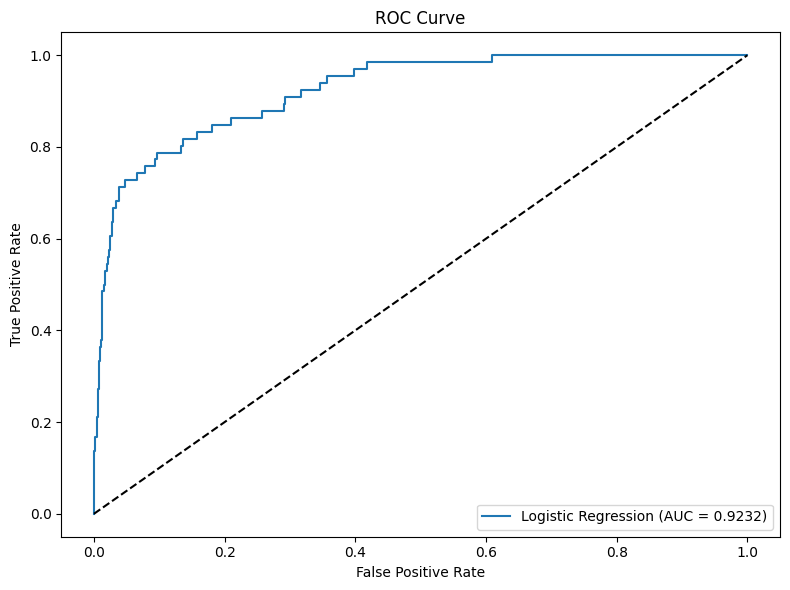

In [126]:
#ROC AUC for logistic regression
y_pred_logistic_proba = logistic_best_model.predict_proba(X_test)[:, 1]
logistic_roc_auc = roc_auc_score(y_test, y_pred_logistic_proba)
print(f"ROC AUC: {logistic_roc_auc:.4f}")
#plot ROC curve for logistic regression
from sklearn.metrics import roc_curve
fpr_logistic, tpr_logistic, _ = roc_curve(y_test, y_pred_logistic_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr_logistic, tpr_logistic, label=f'Logistic Regression (AUC = {logistic_roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

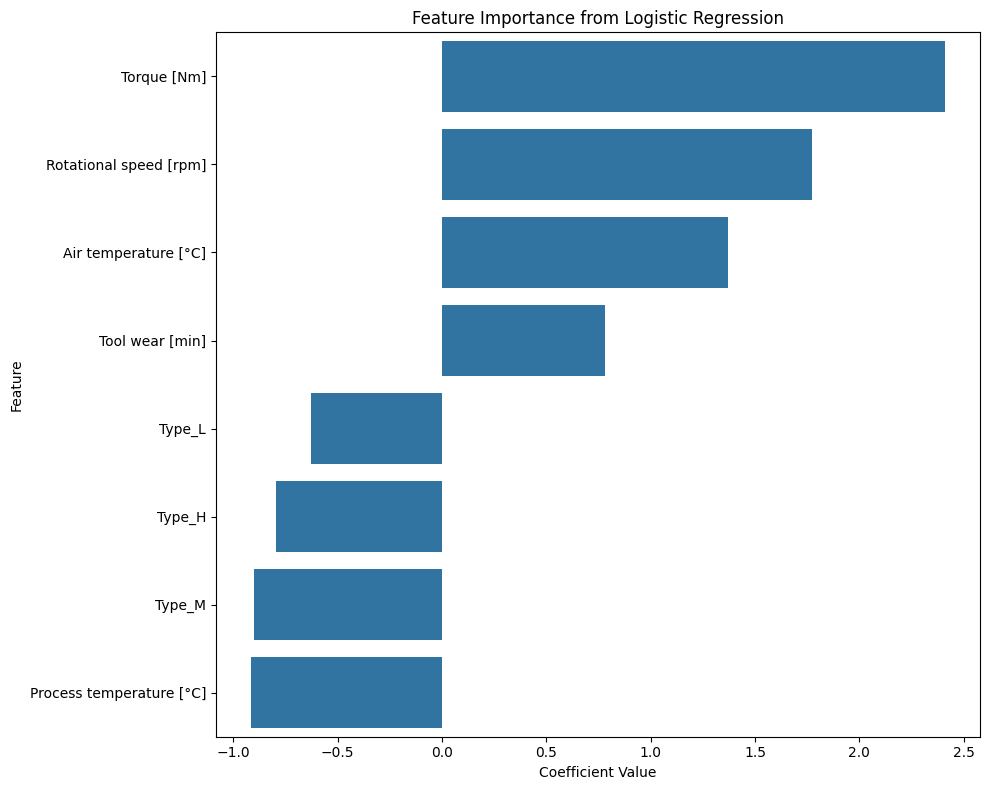

In [145]:
#feature importance for logistic regression
feature_names = numeric_features + list(logistic_best_model.named_steps['preprocessor'].transformers_[1][1].named_steps['onehot'].get_feature_names_out(categorical_features))
coefficients = logistic_best_model.named_steps['classifier'].coef_[0]
feature_importance_logistic = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefficients})
feature_importance_logistic['Importance'] = feature_importance_logistic['Coefficient']
feature_importance_logistic.sort_values(by='Importance', ascending=False, inplace=True)
plt.figure(figsize=(10, 8))
sns.barplot(data=feature_importance_logistic, x='Importance', y='Feature')
plt.title('Feature Importance from Logistic Regression')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [127]:
# decision tree grid search
tree_param_grid = {
    'classifier__max_depth': [None, 5, 10, 20],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4],
    'classifier__class_weight': [None, 'balanced', {0: 1, 1: 5}, {0: 1, 1: 10}]
}
tree_grid_search = GridSearchCV(estimator=tree_pipeline, param_grid=tree_param_grid, cv=5, scoring='f1', n_jobs=-1)
tree_grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Air '
                                                                          'temperature '
                                                                          '[°C]',
                                                                          'Process '
                                                                          'temperature '
                                                                          '[°C]',
                                                                          'Rotational '
                                                                          'speed '
                                                                          '[rpm]',
                                                                          'Torque '
                                                                          '[Nm]',
                                                                          'Tool '
                                                                          'wear '
                                                                          '[min]']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleI...ent')),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Type'])])),
                                       ('classifier',
                                        DecisionTreeClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__class_weight': [None, 'balanced',
                                                      {0: 1, 1: 5},
                                                      {0: 1, 1: 10}],
                         'classifier__max_depth': [None, 5, 10, 20],
                         'classifier__min_samples_leaf': [1, 2, 4],
                         'classifier__min_samples_split': [2, 5, 10]},
             scoring='f1')

In [128]:
# scores for decision tree
tree_best_model = tree_grid_search.best_estimator_
y_pred_tree = tree_best_model.predict(X_test)
tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_precision = precision_score(y_test, y_pred_tree)
tree_recall = recall_score(y_test, y_pred_tree)
tree_f1 = f1_score(y_test, y_pred_tree)
print("Decision Tree Scores:")
print(f"Best Parameters: {tree_grid_search.best_params_}")
print(f"Accuracy: {tree_accuracy:.4f}")
print(f"Precision: {tree_precision:.4f}")
print(f"Recall: {tree_recall:.4f}")
print(f"F1 Score: {tree_f1:.4f}")
#ROC AUC for decision tree
y_pred_tree_proba = tree_best_model.predict_proba(X_test)[:, 1]
tree_roc_auc = roc_auc_score(y_test, y_pred_tree_proba)
print(f"ROC AUC: {tree_roc_auc:.4f}")

Decision Tree Scores:
Best Parameters: {'classifier__class_weight': None, 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 10}
Accuracy: 0.9840
Precision: 0.7656
Recall: 0.7424
F1 Score: 0.7538
ROC AUC: 0.9279


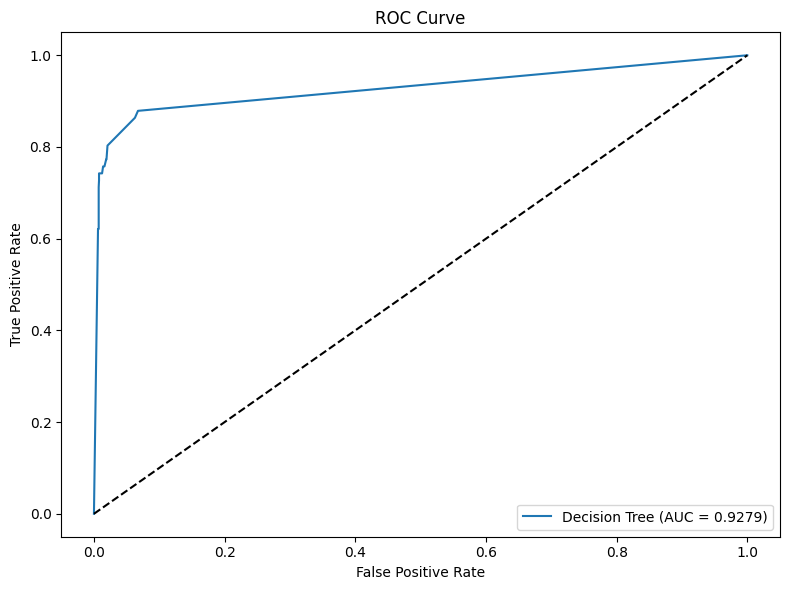

In [129]:
#plot ROC curve for decision tree
fpr_tree, tpr_tree, _ = roc_curve(y_test, y_pred_tree_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr_tree, tpr_tree, label=f'Decision Tree (AUC = {tree_roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

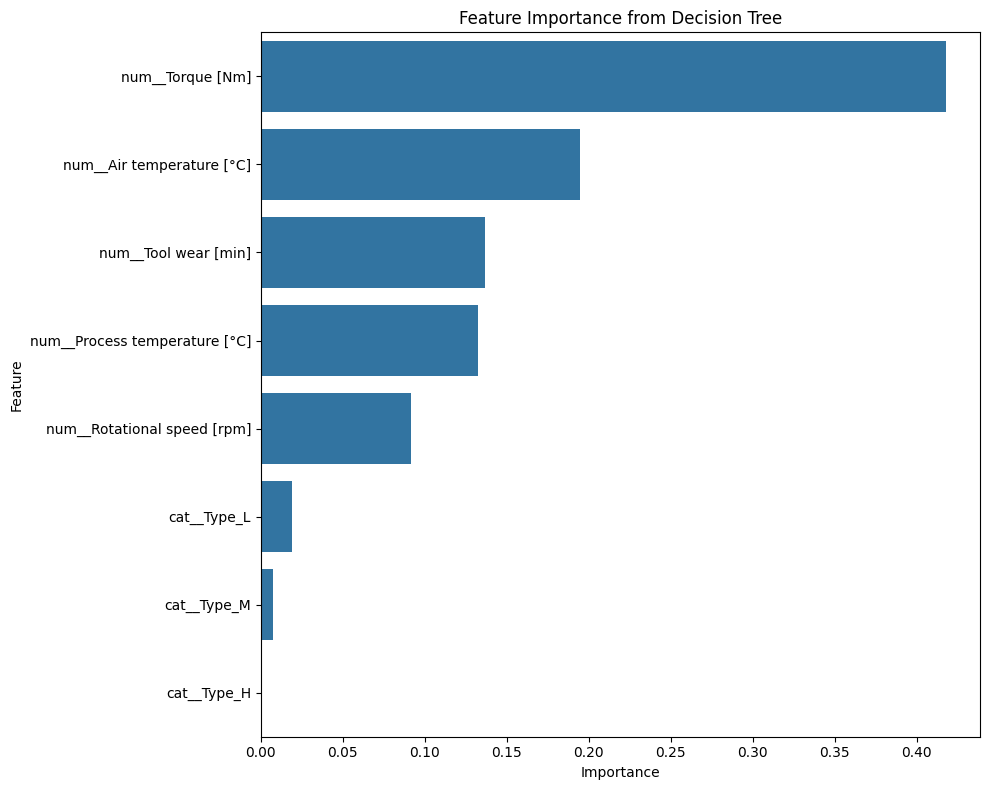

In [144]:
# Get the best pipeline
tree_best_model = tree_grid_search.best_estimator_

# Get the fitted preprocessor and classifier
preprocessor = tree_best_model.named_steps['preprocessor']
classifier = tree_best_model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# most importatn features for decision tree
importances = classifier.feature_importances_
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=feature_importance_df, x='Importance', y='Feature')
plt.title('Feature Importance from Decision Tree')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


In [139]:
#random forest grid search
forest_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2],
    'classifier__class_weight': [None, 'balanced', {0: 1, 1: 5}, {0: 1, 1: 10}]
}
forest_grid_search = GridSearchCV(estimator=forest_pipeline, param_grid=forest_param_grid, cv=5, scoring='f1', n_jobs=-1)
forest_grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Air '
                                                                          'temperature '
                                                                          '[°C]',
                                                                          'Process '
                                                                          'temperature '
                                                                          '[°C]',
                                                                          'Rotational '
                                                                          'speed '
                                                                          '[rpm]',
                                                                          'Torque '
                                                                          '[Nm]',
                                                                          'Tool '
                                                                          'wear '
                                                                          '[min]']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleI...
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Type'])])),
                                       ('classifier',
                                        RandomForestClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__class_weight': [None, 'balanced',
                                                      {0: 1, 1: 5},
                                                      {0: 1, 1: 10}],
                         'classifier__max_depth': [None, 10, 20],
                         'classifier__min_samples_leaf': [1, 2],
                         'classifier__min_samples_split': [2, 5],
                         'classifier__n_estimators': [100, 200]},
             scoring='f1')

In [140]:
# scores for random forest
forest_best_model = forest_grid_search.best_estimator_
y_pred_forest = forest_best_model.predict(X_test)
forest_accuracy = accuracy_score(y_test, y_pred_forest)
forest_precision = precision_score(y_test, y_pred_forest)
forest_recall = recall_score(y_test, y_pred_forest)
forest_f1 = f1_score(y_test, y_pred_forest)
print("Random Forest Scores:")
print(f"Best Parameters: {forest_grid_search.best_params_}")
print(f"Accuracy: {forest_accuracy:.4f}")
print(f"Precision: {forest_precision:.4f}")
print(f"Recall: {forest_recall:.4f}")
print(f"F1 Score: {forest_f1:.4f}")
#ROC AUC for random forest
y_pred_forest_proba = forest_best_model.predict_proba(X_test)[:, 1]
forest_roc_auc = roc_auc_score(y_test, y_pred_forest_proba)
print(f"ROC AUC: {forest_roc_auc:.4f}")

Random Forest Scores:
Best Parameters: {'classifier__class_weight': {0: 1, 1: 5}, 'classifier__max_depth': None, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}
Accuracy: 0.9860
Precision: 0.8800
Recall: 0.6667
F1 Score: 0.7586
ROC AUC: 0.9815


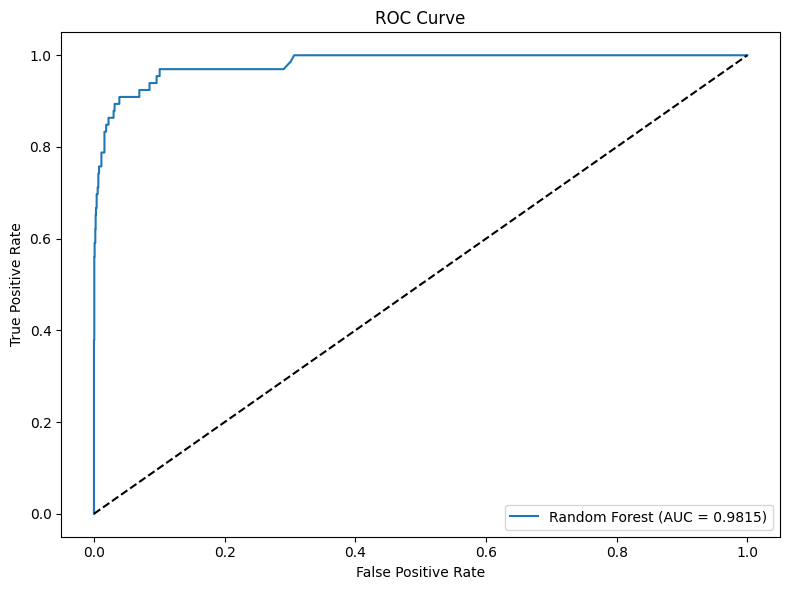

In [141]:
# plot ROC curve for random forest
fpr_forest, tpr_forest, _ = roc_curve(y_test, y_pred_forest_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr_forest, tpr_forest, label=f'Random Forest (AUC = {forest_roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

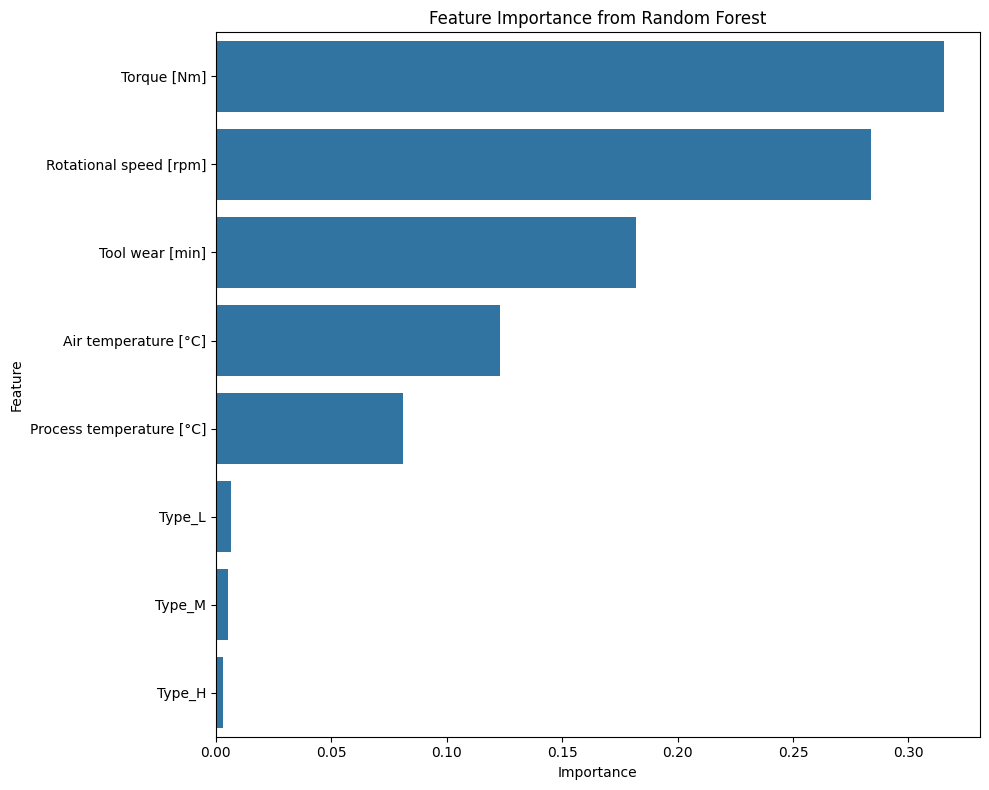

In [146]:
# feature importance for random forest
importances = forest_best_model.named_steps['classifier'].feature_importances_
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=feature_importance_df, x='Importance', y='Feature')
plt.title('Feature Importance from Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [147]:
# predicting type of failure
df_multiclass = df.copy()
y_multi = df_multiclass['Failure Type']
X_multi = df_multiclass.drop(columns=['UDI', 'Product ID', 'Target', 'Failure Type'])

#split data
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42, stratify=y_multi)


In [148]:
# preprocessing pipeline for multiclass classification
numeric_features_multi = ['Air temperature [°C]', 'Process temperature [°C]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
categorical_features_multi = ['Type']
numeric_transformer_multi = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer_multi = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor_multi = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_multi, numeric_features_multi),
        ('cat', categorical_transformer_multi, categorical_features_multi)
    ])

In [154]:
# multiclass classification pipeline
multi_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_multi),
    ('classifier', RandomForestClassifier(random_state=42))
])
# grid search for multiclass classification
multi_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2],
    'classifier__class_weight': [None, 'balanced'] 
}
multi_grid_search = GridSearchCV(estimator=multi_pipeline, param_grid=multi_param_grid, cv=5, scoring='recall_macro', n_jobs=-1)
multi_grid_search.fit(X_train_multi, y_train_multi)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['Air '
                                                                          'temperature '
                                                                          '[°C]',
                                                                          'Process '
                                                                          'temperature '
                                                                          '[°C]',
                                                                          'Rotational '
                                                                          'speed '
                                                                          '[rpm]',
                                                                          'Torque '
                                                                          '[Nm]',
                                                                          'Tool '
                                                                          'wear '
                                                                          '[min]']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleI...
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Type'])])),
                                       ('classifier',
                                        RandomForestClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__class_weight': [None, 'balanced'],
                         'classifier__max_depth': [None, 10, 20],
                         'classifier__min_samples_leaf': [1, 2],
                         'classifier__min_samples_split': [2, 5],
                         'classifier__n_estimators': [100, 200]},
             scoring='recall_macro')

In [155]:
# scores for multiclass classification
multi_best_model = multi_grid_search.best_estimator_
y_pred_multi = multi_best_model.predict(X_test_multi)
multi_accuracy = accuracy_score(y_test_multi, y_pred_multi)
multi_precision = precision_score(y_test_multi, y_pred_multi, average='macro')
multi_recall = recall_score(y_test_multi, y_pred_multi, average='macro')
multi_f1 = f1_score(y_test_multi, y_pred_multi, average='macro')
print("Multiclass Classification Scores:")
print(f"Best Parameters: {multi_grid_search.best_params_}")
print(f"Accuracy: {multi_accuracy:.4f}")
print(f"Precision: {multi_precision:.4f}")
print(f"Recall: {multi_recall:.4f}")
print(f"F1 Score: {multi_f1:.4f}")


Multiclass Classification Scores:
Best Parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}
Accuracy: 0.9714
Precision: 0.6776
Recall: 0.6705
F1 Score: 0.6492


In [156]:
#classification report
from sklearn.metrics import classification_report
print("Classification Report:")
print(classification_report(y_test_multi, y_pred_multi))

Classification Report:
                          precision    recall  f1-score   support

Heat Dissipation Failure       0.53      0.95      0.68        22
              No Failure       0.99      0.98      0.99      1929
      Overstrain Failure       0.82      0.56      0.67        16
           Power Failure       0.92      0.63      0.75        19
       Tool Wear Failure       0.13      0.22      0.17         9

                accuracy                           0.97      1995
               macro avg       0.68      0.67      0.65      1995
            weighted avg       0.98      0.97      0.97      1995



In [160]:
# see examples that where flagged as heat dissipation failure
heat_dissipation_failures = df_multiclass.loc[y_test_multi.index[(y_test_multi == 'Heat Dissipation Failure') & (y_pred_multi == 'Heat Dissipation Failure')]]
print("Examples flagged as Heat Dissipation Failure:")
print(heat_dissipation_failures.head())

Examples flagged as Heat Dissipation Failure:
       UDI Product ID Type  Rotational speed [rpm]  Torque [Nm]  \
4449  4450     M19309    M                    1378         54.3   
4621  4622     L51801    L                    1341         51.0   
4761  4762     H34175    H                    1332         52.7   
4720  4721     M19580    M                    1353         44.1   
4651  4652     L51831    L                    1349         51.1   

      Tool wear [min]  Target              Failure Type  Air temperature [°C]  \
4449              165       1  Heat Dissipation Failure                 29.25   
4621              174       1  Heat Dissipation Failure                 29.85   
4761               66       1  Heat Dissipation Failure                 30.55   
4720              192       1  Heat Dissipation Failure                 30.25   
4651                9       1  Heat Dissipation Failure                 30.05   

      Process temperature [°C]  
4449                     37.15 

In [162]:
import joblib

# save the best random forest model for binary classification
joblib.dump(forest_best_model, '../models/failure_model.pkl')


['../models/failure_model.pkl']